# LAB1 – Bài 2: Yêu cầu lập trình
**Sinh viên:** Đinh Văn Bình – **MSSV:** 6351071007

## Câu 3: Vẽ biểu đồ khảo sát sự liên quan giữa Độ tuổi (age), Giới tính (sex) và khả năng sống sót (survived)

In [1]:
print('Họ tên: Đinh Văn Bình - MSSV: 6351071007')

Họ tên: Đinh Văn Bình - MSSV: 6351071007


### Bước 1. Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt

with open('titanic.csv') as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

print('Kích thước dữ liệu (dòng, cột):', df.shape)

Kích thước dữ liệu (dòng, cột): (1309, 14)


### Bước 2. Vẽ biểu đồ phân bố tuổi theo khả năng sống sót, tách riêng Nữ và Nam
- Màu xanh lá (`g`): sống sót, màu vàng (`y`): không sống sót.
- Bỏ các giá trị tuổi bị rỗng bằng `dropna()`.

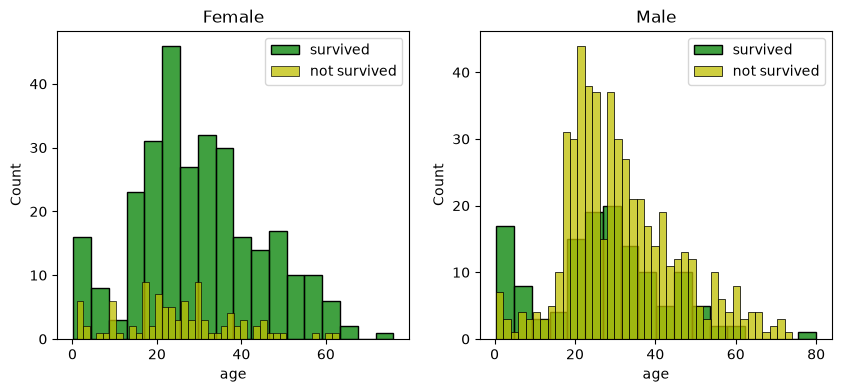

In [3]:
survived = 'survived'
not_survived = 'not survived'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

ax = sns.histplot(women[women['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[0], kde=False, color='g')
ax = sns.histplot(women[women['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[0], kde=False, color='y')
ax.legend()
ax.set_title('Female')

ax = sns.histplot(men[men['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[1], kde=False, color='g')
ax = sns.histplot(men[men['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[1], kde=False, color='y')
ax.legend()
_ = ax.set_title('Male')

### Bước 3. Tỷ lệ sống sót theo giới tính và nhóm tuổi (số liệu minh họa cho nhận xét)

In [4]:
print('Tỷ lệ sống sót theo giới tính (%):')
print((df.groupby('sex')['survived'].mean() * 100).round(1))

age_group = pd.cut(df['age'], bins=[0, 10, 18, 27, 40, 60, 80])
rate = (df.groupby([age_group, 'sex'], observed=True)['survived'].mean() * 100).round(1).unstack()
count = df.groupby([age_group, 'sex'], observed=True)['survived'].size().unstack()
print('\nTỷ lệ sống sót (%) theo nhóm tuổi và giới tính:')
print(rate)
print('\nSố hành khách theo nhóm tuổi và giới tính:')
print(count)

Tỷ lệ sống sót theo giới tính (%):
sex
female    72.7
male      19.1
Name: survived, dtype: float64

Tỷ lệ sống sót (%) theo nhóm tuổi và giới tính:
sex       female  male
age                   
(0, 10]     61.0  55.6
(10, 18]    74.5  12.5
(18, 27]    73.3  19.4
(27, 40]    77.0  18.8
(40, 60]    83.1  18.7
(60, 80]    85.7   7.7

Số hành khách theo nhóm tuổi và giới tính:
sex       female  male
age                   
(0, 10]       41    45
(10, 18]      51    56
(18, 27]     105   206
(27, 40]     113   202
(40, 60]      71   123
(60, 80]       7    26


### Nhận xét
Từ biểu đồ và bảng tỷ lệ trên có thể rút ra vài nhận xét như sau:
- **Giới tính ảnh hưởng rất lớn đến khả năng sống sót:** tỷ lệ sống sót của nữ là **72.7%**, của nam chỉ **19.1%**. Ở biểu đồ Female, cột xanh (sống sót) cao vượt trội cột vàng; ở biểu đồ Male thì ngược lại.
- **Nam giới:** xác suất sống sót cao ở **trẻ em dưới 10 tuổi** (55.6%), đây là nhóm duy nhất mà nam có cột xanh cao hơn cột vàng (ưu tiên “phụ nữ và trẻ em trước”). Từ trên 10 tuổi trở đi, tỷ lệ sống sót của nam giảm mạnh, chỉ còn khoảng 12–19%.
- **Số nam không sống sót nhiều nhất ở độ tuổi khoảng 18 – 30**, đây cũng là nhóm tuổi đông hành khách nam nhất (206 người ở nhóm 18–27).
- **Nữ giới:** cơ hội sống sót cao ở hầu hết các độ tuổi, đặc biệt từ **12 đến 40 tuổi** là vùng có nhiều nữ sống sót nhất; tỷ lệ sống sót của nữ có xu hướng tăng theo tuổi (61% ở nhóm dưới 10 tuổi → trên 80% ở nhóm trên 40 tuổi).
- **Nhìn chung**, ở mọi lứa tuổi, tỷ lệ sống sót của nữ đều cao hơn nam; chênh lệch nhỏ nhất ở trẻ em (dưới 10 tuổi) và lớn nhất ở người trưởng thành.
- Kết luận: `sex` và `age` là hai thuộc tính quan trọng để dự đoán khả năng sống sót, trong đó `sex` có ảnh hưởng mạnh nhất.